# OLD VERSION


=== [train2016Q1_2023Q4_test2024Q1_2025Q4] TRAIN OLS(HAC1) coef/t/p ===
 term      coef   se_HAC     t_HAC    p_HAC sign  sig_10%  sig_5%  sig_1%
const -0.051758 0.023918 -2.163991 0.039478    -     True    True   False
X1_l1  0.000158 0.000055  2.882458 0.007649    +     True    True    True
   X2 -5.233368 2.000743 -2.615713 0.014399    -     True    True   False
X3_l1  0.000215 0.000035  6.124658 0.000002    +     True    True    True
 X4_z  0.045814 0.020082  2.281383 0.030633    +     True    True   False

=== [train2016Q1_2023Q4_test2024Q1_2025Q4] TRAIN VIF ===
 term      VIF
   X2 2.186532
 X4_z 2.039591
X3_l1 1.154176
X1_l1 1.080285


C:\PDS\Streamlit\streamlit_env\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


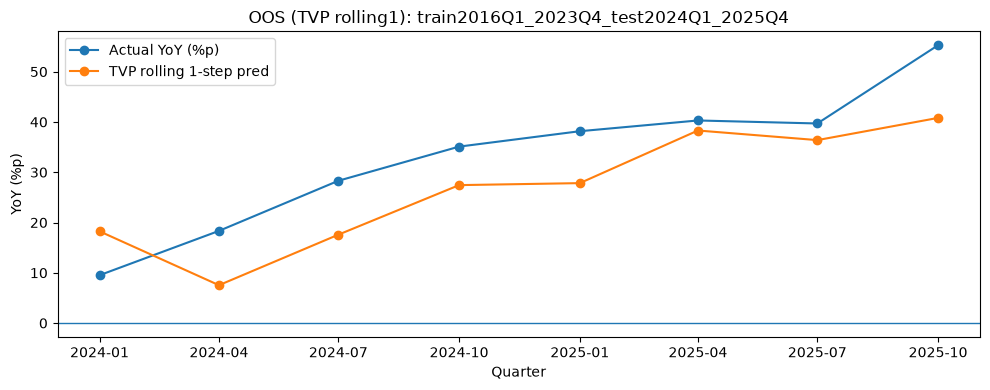


=== SUMMARY (sorted by RMSE_pp) ===
  R2_log  RMSE_log  MAE_log  RMSE_pp   MAE_pp  mean_actual_pp  mean_pred_pp                                 name train_start train_end test_start test_end  n_train  n_test  standardize_x_tvp
0.491384  0.072832 0.066473 9.334766 8.500402       33.083046     26.765513 train2016Q1_2023Q4_test2024Q1_2025Q4      2016Q1    2023Q4     2024Q1   2025Q4       32       8               True

Saved: tvp_oos_core_nodxy_b4_periods_with_diag.xlsx


In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
from statsmodels.stats.outliers_influence import variance_inflation_factor

# ============================================================
# TVP rolling 1-step OOS backtest
# Prediction engine: CORE(no DXY) + X4_raw YoY
#
#   yoy_log_gold_t ~ X1_{t-1} + X2_t + X3_{t-1} + X4_z,t
#
# - Train/Test windows are configurable via PERIODS below.
# - Uses train-only z-score for X4_raw YoY (information leakage prevented).
# - Optionally standardizes ALL X (train stats) for TVP stability.
# - For interpretability on TRAIN:
#     * OLS(HAC) coef / t / p
#     * VIF (multicollinearity)
#
# Saves:
#   tvp_oos_core_nodxy_b4_periods_with_diag.xlsx
#   tvp_oos_<period_name>.png
# ============================================================

# ----------------------------
# CONFIG (edit these)
# ----------------------------
INPUT_XLSX = r"global_quarterly_data_260511.xlsx"   # <- change to your file path
SHEET_NAME = "Sheet1"                                 # <- sheet name or 0-based index

COL = {
    "quarter": "quarter",        # '2010Q1' format
    "gold": "금 가격",
    "X3_raw": "X3_raw",
    "X1_raw": "X1_raw",
    "X2_raw": "X2_raw",
    "X4_raw": "X4_raw",
    # optional narrative-only (not used in model)
    "dxy": "달러 인덱스",
}

# Backtest windows (add more dicts to compare different periods)
PERIODS = [
    dict(
        name="train2016Q1_2023Q4_test2024Q1_2025Q4",
        train_start="2016Q1",
        train_end="2023Q4",
        test_start="2024Q1",
        test_end="2025Q4",
    ),
]

STANDARDIZE_ALL_X_FOR_TVP = True
TVP_MAXITER = 3000

# OLS(HAC) diagnostics settings
HAC_LAGS = 1  # typical: 1 for quarterly

# ----------------------------
# Helpers
# ----------------------------
def q_to_ts(q: str) -> pd.Timestamp:
    return pd.Period(q, freq="Q").to_timestamp()

def oos_metrics(y_true_log: np.ndarray, y_pred_log: np.ndarray) -> dict:
    y_true_log = np.asarray(y_true_log, float)
    y_pred_log = np.asarray(y_pred_log, float)

    sse = float(np.sum((y_true_log - y_pred_log) ** 2))
    sst = float(np.sum((y_true_log - np.mean(y_true_log)) ** 2))
    r2 = 1 - sse / sst if sst > 0 else np.nan
    rmse_log = float(np.sqrt(np.mean((y_true_log - y_pred_log) ** 2)))
    mae_log = float(np.mean(np.abs(y_true_log - y_pred_log)))

    true_pp = (np.exp(y_true_log) - 1) * 100
    pred_pp = (np.exp(y_pred_log) - 1) * 100
    err_pp = true_pp - pred_pp
    rmse_pp = float(np.sqrt(np.mean(err_pp ** 2)))
    mae_pp = float(np.mean(np.abs(err_pp)))

    return {
        "R2_log": r2,
        "RMSE_log": rmse_log,
        "MAE_log": mae_log,
        "RMSE_pp": rmse_pp,
        "MAE_pp": mae_pp,
        "mean_actual_pp": float(true_pp.mean()),
        "mean_pred_pp": float(pred_pp.mean()),
    }

def tvp_rolling1(train_df: pd.DataFrame, test_df: pd.DataFrame, y_col: str, x_cols: list[str],
                 standardize_x: bool=True, maxiter: int=3000):
    """
    Fit TVP on train only. Filter full(train+test) with train params.
    Produce rolling 1-step predictions over test (dynamic=False).
    """
    full = pd.concat([train_df, test_df], ignore_index=True).copy()

    mu = None
    sd = None
    if standardize_x:
        mu = train_df[x_cols].mean()
        sd = train_df[x_cols].std(ddof=0).replace(0, 1.0)
        full[x_cols] = (full[x_cols] - mu) / sd

    tr = full.iloc[:len(train_df)].copy()
    te = full.iloc[len(train_df):].copy()

    exog_tr = np.column_stack([np.ones(len(tr)), tr[x_cols].astype(float).to_numpy()])
    mod_tr = sm.tsa.SARIMAX(
        endog=tr[y_col].astype(float).to_numpy(),
        exog=exog_tr,
        order=(0, 0, 0),
        trend="n",
        time_varying_regression=True,
        mle_regression=False,
    )
    try:
        res_tr = mod_tr.fit(disp=False, maxiter=maxiter)
    except Exception:
        res_tr = mod_tr.fit(disp=False, maxiter=maxiter * 2, method="powell")

    exog_full = np.column_stack([np.ones(len(full)), full[x_cols].astype(float).to_numpy()])
    mod_full = sm.tsa.SARIMAX(
        endog=full[y_col].astype(float).to_numpy(),
        exog=exog_full,
        order=(0, 0, 0),
        trend="n",
        time_varying_regression=True,
        mle_regression=False,
    )
    res_f = mod_full.filter(res_tr.params)

    start_i = len(train_df)
    end_i = len(full) - 1
    pred = res_f.get_prediction(start=start_i, end=end_i, dynamic=False)
    yhat = np.asarray(pred.predicted_mean)

    te_out = te[["quarter", "qdate", y_col] + x_cols].copy()
    te_out["pred_1step"] = yhat
    return te_out, res_tr, mu, sd

def fit_ols_hac(train_df: pd.DataFrame, y_col: str, x_cols: list[str], hac_lags: int=1) -> pd.DataFrame:
    """
    OLS on train with HAC SEs.
    Returns coef/t/p table.
    """
    X = sm.add_constant(train_df[x_cols].astype(float))
    y = train_df[y_col].astype(float)
    ols = sm.OLS(y, X).fit()
    hac = ols.get_robustcov_results(cov_type="HAC", maxlags=hac_lags)

    tbl = pd.DataFrame({
        "term": ["const"] + x_cols,
        "coef": hac.params,
        "se_HAC": hac.bse,
        "t_HAC": hac.tvalues,
        "p_HAC": hac.pvalues,
    })
    tbl["sign"] = np.where(tbl["coef"] > 0, "+", np.where(tbl["coef"] < 0, "-", "0"))
    tbl["sig_10%"] = tbl["p_HAC"] <= 0.10
    tbl["sig_5%"]  = tbl["p_HAC"] <= 0.05
    tbl["sig_1%"]  = tbl["p_HAC"] <= 0.01
    return tbl

def vif_table(train_df: pd.DataFrame, x_cols: list[str]) -> pd.DataFrame:
    Xmat = train_df[x_cols].astype(float).to_numpy()
    rows = []
    for i, name in enumerate(x_cols):
        rows.append({"term": name, "VIF": float(variance_inflation_factor(Xmat, i))})
    return pd.DataFrame(rows).sort_values("VIF", ascending=False)

# ----------------------------
# Load
# ----------------------------
df0 = pd.read_excel(INPUT_XLSX, sheet_name=SHEET_NAME).copy()

for k, colname in COL.items():
    if colname not in df0.columns:
        if k == "dxy":
            continue  # narrative-only
        raise ValueError(f"Missing column '{colname}' for key '{k}'. Fix COL mapping.")

df = pd.DataFrame({
    "quarter": df0[COL["quarter"]].astype(str),
    "gold": pd.to_numeric(df0[COL["gold"]], errors="coerce"),
    "X3_raw": pd.to_numeric(df0[COL["X3_raw"]], errors="coerce"),
    "X1_raw": pd.to_numeric(df0[COL["X1_raw"]], errors="coerce"),
    "X2_raw": pd.to_numeric(df0[COL["X2_raw"]], errors="coerce"),
    "X4_raw": pd.to_numeric(df0[COL["X4_raw"]], errors="coerce"),
})
if COL.get("dxy") in df0.columns:
    df["dxy"] = pd.to_numeric(df0[COL["dxy"]], errors="coerce")

df["qdate"] = pd.PeriodIndex(df["quarter"], freq="Q").to_timestamp()
df = df.sort_values("qdate").reset_index(drop=True)

# ----------------------------
# Feature engineering
# ----------------------------
df["log_gold"] = np.log(df["gold"])
df["yoy_log_gold"] = df["log_gold"] - df["log_gold"].shift(4)

df["X1"] = df["X1_raw"] - df["X1_raw"].shift(4)
df["X1_l1"] = df["X1"].shift(1)

df["X2"] = df["X2_raw"] - df["X2_raw"].shift(4)

df["X3"] = df["X3_raw"].rolling(4, min_periods=4).sum()
df["X3_l1"] = df["X3"].shift(1)

df["log_X4"] = np.log(df["X4_raw"])
df["X4"] = df["log_X4"] - df["log_X4"].shift(4)

# narrative-only
if "dxy" in df.columns:
    df["log_dxy"] = np.log(df["dxy"])
    df["yoy_log_dxy"] = df["log_dxy"] - df["log_dxy"].shift(4)

Y = "yoy_log_gold"
X_BASE = ["X1_l1", "X2", "X3_l1", "X4"]

# ----------------------------
# Run backtests
# ----------------------------
all_summaries = []
oos_sheets = {}
ols_sheets = {}
vif_sheets = {}

for cfg in PERIODS:
    name = cfg["name"]
    train_start_ts = q_to_ts(cfg["train_start"])
    train_end_ts = q_to_ts(cfg["train_end"])
    test_start_ts = q_to_ts(cfg["test_start"])
    test_end_ts = q_to_ts(cfg["test_end"])

    cols = ["quarter", "qdate", Y] + X_BASE
    if "yoy_log_dxy" in df.columns:
        cols += ["yoy_log_dxy"]
    d = df[cols].dropna().copy().reset_index(drop=True)

    train = d[(d["qdate"] >= train_start_ts) & (d["qdate"] <= train_end_ts)].copy().reset_index(drop=True)
    test = d[(d["qdate"] >= test_start_ts) & (d["qdate"] <= test_end_ts)].copy().reset_index(drop=True)

    if len(train) < 20:
        raise ValueError(f"[{name}] Train too small: {len(train)} rows")
    if len(test) < 4:
        raise ValueError(f"[{name}] Test too small: {len(test)} rows")

    # X4_raw z-score (train-only, leakage-free)
    mu_b4 = float(train["X4"].mean())
    sd_b4 = float(train["X4"].std(ddof=0))
    sd_b4 = sd_b4 if sd_b4 != 0 else 1.0

    train = train.copy()
    test = test.copy()
    train["X4_z"] = (train["X4"] - mu_b4) / sd_b4
    test["X4_z"] = (test["X4"] - mu_b4) / sd_b4

    xcols = ["X1_l1", "X2", "X3_l1", "X4_z"]

    # TRAIN diagnostics (OLS HAC + VIF) on *raw* (not TVP-standardized) regressors
    ols_tbl = fit_ols_hac(train, Y, xcols, hac_lags=HAC_LAGS)
    vif_tbl = vif_table(train, xcols)
    ols_sheets[name] = ols_tbl
    vif_sheets[name] = vif_tbl

    print(f"\n=== [{name}] TRAIN OLS(HAC{HAC_LAGS}) coef/t/p ===")
    print(ols_tbl.to_string(index=False))
    print(f"\n=== [{name}] TRAIN VIF ===")
    print(vif_tbl.to_string(index=False))

    # TVP rolling 1-step
    oos_df, _, _, _ = tvp_rolling1(
        train_df=train,
        test_df=test,
        y_col=Y,
        x_cols=xcols,
        standardize_x=STANDARDIZE_ALL_X_FOR_TVP,
        maxiter=TVP_MAXITER
    )

    met = oos_metrics(oos_df[Y], oos_df["pred_1step"])
    met.update({
        "name": name,
        "train_start": cfg["train_start"],
        "train_end": cfg["train_end"],
        "test_start": cfg["test_start"],
        "test_end": cfg["test_end"],
        "n_train": len(train),
        "n_test": len(test),
        "standardize_x_tvp": STANDARDIZE_ALL_X_FOR_TVP,
    })
    all_summaries.append(met)

    oos_df = oos_df.copy()
    oos_df["actual_pp"] = (np.exp(oos_df[Y]) - 1) * 100
    oos_df["pred_pp"] = (np.exp(oos_df["pred_1step"]) - 1) * 100
    oos_df["err_pp"] = oos_df["actual_pp"] - oos_df["pred_pp"]

    # attach narrative DXY yoy (context only)
    if "yoy_log_dxy" in test.columns:
        oos_df = oos_df.merge(test[["quarter", "yoy_log_dxy"]], on="quarter", how="left")

    oos_sheets[name] = oos_df

    # Plot
    plt.figure(figsize=(10, 4))
    plt.plot(oos_df["qdate"], oos_df["actual_pp"], marker="o", label="Actual YoY (%p)")
    plt.plot(oos_df["qdate"], oos_df["pred_pp"], marker="o", label="TVP rolling 1-step pred")
    plt.axhline(0, linewidth=1)
    plt.title(f"OOS (TVP rolling1): {name}")
    plt.ylabel("YoY (%p)")
    plt.xlabel("Quarter")
    plt.legend()
    plt.tight_layout()

    import os

    #OUT_DIR = r"D:\projects\pds_university\2605_gold_price"
    #os.makedirs(OUT_DIR, exist_ok=True)

    #png = os.path.join(OUT_DIR, f"tvp_oos_{name}.png")
    plt.savefig(f"tvp_oos_{name}.png", dpi=200)
    
    plt.show()
    plt.close()

summary_df = pd.DataFrame(all_summaries).sort_values(["RMSE_pp", "MAE_pp"])
print("\n=== SUMMARY (sorted by RMSE_pp) ===")
print(summary_df.to_string(index=False))

# Save workbook
out_xlsx = r"tvp_oos_core_nodxy_b4_periods_with_diag.xlsx"
with pd.ExcelWriter(out_xlsx, engine="openpyxl") as writer:
    summary_df.to_excel(writer, sheet_name="summary", index=False)
    for name in oos_sheets.keys():
        oos_sheets[name].to_excel(writer, sheet_name=f"oos_{name[:24]}", index=False)
        ols_sheets[name].to_excel(writer, sheet_name=f"ols_{name[:24]}", index=False)
        vif_sheets[name].to_excel(writer, sheet_name=f"vif_{name[:24]}", index=False)

print(f"\nSaved: {out_xlsx}")


In [2]:
X5 = np.array(pd.read_excel("global_quarterly_data_260604.xlsx")['X5_raw'])
X6 = np.array(pd.read_excel("global_quarterly_data_260604.xlsx")['X6_raw'])

In [3]:
df['X5'] = np.array(list(X5) + [np.nan] * 2)
df['X6'] = np.array(list(X6) + [np.nan] * 2)

# X5 yoy log lag1
df["log_X5"] = np.log(df["X5"])
df["X5"] = df["log_X5"] - df["log_X5"].shift(4)
df["X5_l1"] = df["X5"].shift(1)

# X6 level lag1
df["X6_l1"] = df["X6"].shift(1)

In [4]:
df

,quarter,gold,X3_raw,X1_raw,X2_raw,X4_raw,dxy,qdate,log_gold,yoy_log_gold,...,X3_l1,log_X4,X4,log_dxy,yoy_log_dxy,X5,X6,log_X5,X5_l1,X6_l1
0,2010Q1,1109.115079,59.710231,283.332885,0.014389,32220.303333,79.740841,2010-01-01,7.011318,NaN,...,NaN,10.380352,NaN,4.378782,NaN,NaN,0.617866,15.931073,NaN,NaN
1,2010Q2,1196.741803,14.214257,619.535941,0.013564,33287.276667,84.547446,2010-04-01,7.087358,NaN,...,NaN,10.412931,NaN,4.437313,NaN,NaN,0.625629,15.971823,NaN,0.617866
2,2010Q3,1226.750000,24.035880,382.035757,0.010567,34376.956667,82.267076,2010-07-01,7.112124,NaN,...,NaN,10.445142,NaN,4.409971,NaN,NaN,0.618217,16.015798,NaN,0.625629
3,2010Q4,1366.782258,-18.809865,368.045513,0.007547,35127.193333,78.849477,2010-10-01,7.220215,NaN,...,NaN,10.466731,NaN,4.367541,NaN,NaN,0.619359,16.055732,NaN,0.618217
4,2011Q1,1386.265873,142.463761,353.435934,0.010790,35904.253333,78.010953,2011-01-01,7.234369,0.223051,...,79.150503,10.488611,0.108259,4.356849,-0.021933,0.152076,0.618158,16.083149,NaN,0.619359
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61,2025Q2,3280.352459,179.252016,483.651404,0.020782,89698.950000,99.583712,2025-04-01,8.095706,0.338580,...,1016.103165,11.404214,0.053659,4.600999,-0.053106,0.047423,0.570801,17.181985,0.049581,0.585177
62,2025Q3,3456.543846,226.252312,553.864491,0.018810,90655.570000,97.752530,2025-07-01,8.148024,0.334315,...,983.835589,11.414823,0.049294,4.582439,-0.047282,0.067321,0.569322,17.226602,0.047423,0.570801
63,2025Q4,4135.235484,207.641660,602.921331,0.018279,91938.920000,98.812323,2025-10-01,8.327300,0.439950,...,1009.087785,11.428880,0.048958,4.593222,-0.063236,0.067382,0.567702,17.245318,0.067321,0.569322
64,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaN,...,850.143731,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.067382,0.567702


In [5]:
def tvp_rolling1(train_df: pd.DataFrame, test_df: pd.DataFrame, y_col: str, x_cols: list[str],
                 standardize_x: bool=True, maxiter: int=3000):
    """
    Fit TVP on train only. Filter full(train+test) with train params.
    Produce rolling 1-step predictions over test (dynamic=False).
    """
    full = pd.concat([train_df, test_df], ignore_index=True).copy()

    mu = None
    sd = None
    if standardize_x:
        mu = train_df[x_cols].mean()
        sd = train_df[x_cols].std(ddof=0).replace(0, 1.0)
        full[x_cols] = (full[x_cols] - mu) / sd

    tr = full.iloc[:len(train_df)].copy()
    te = full.iloc[len(train_df):].copy()

    exog_tr = np.column_stack([np.ones(len(tr)), tr[x_cols].astype(float).to_numpy()])
    mod_tr = sm.tsa.SARIMAX(
        endog=tr[y_col].astype(float).to_numpy(),
        exog=exog_tr,
        order=(0, 0, 0),
        trend="n",
        time_varying_regression=True,
        mle_regression=False,
    )
    try:
        res_tr = mod_tr.fit(disp=False, maxiter=maxiter)
    except Exception:
        res_tr = mod_tr.fit(disp=False, maxiter=maxiter * 2, method="powell")

    exog_full = np.column_stack([np.ones(len(full)), full[x_cols].astype(float).to_numpy()])
    mod_full = sm.tsa.SARIMAX(
        endog=full[y_col].astype(float).to_numpy(),
        exog=exog_full,
        order=(0, 0, 0),
        trend="n",
        time_varying_regression=True,
        mle_regression=False,
    )
    res_f = mod_full.filter(res_tr.params)
    print(res_f.model.state_names)
    
    coef_df = pd.DataFrame({
        "quarter": full["quarter"],
        "qdate": full["qdate"],
    })

    coef_df["const"] = res_f.filtered_state[0] #2, 0

    for p, var in enumerate(x_cols):
        coef_df[var] = res_f.filtered_state[p + 1] #3, 1

    start_i = len(train_df)
    end_i = len(full) - 1
    pred = res_f.get_prediction(start=start_i, end=end_i, dynamic=False)
    yhat = np.asarray(pred.predicted_mean)

    te_out = te[["quarter", "qdate", y_col] + x_cols].copy()
    te_out["pred_1step"] = yhat
    return te_out, res_tr, mu, sd, coef_df


=== [train2016Q1_2023Q4_test2024Q1_2025Q4] TRAIN OLS(HAC1) coef/t/p ===
 term      coef   se_HAC     t_HAC    p_HAC sign  sig_10%  sig_5%  sig_1%
const -0.080140 0.742444 -0.107941 0.914904    -    False   False   False
X1_l1  0.000166 0.000041  4.016816 0.000474    +     True    True    True
   X2 -5.877830 3.198041 -1.837947 0.077983    -     True   False   False
X3_l1  0.000189 0.000078  2.428749 0.022677    +     True    True   False
 X4_z  0.022417 0.041892  0.535099 0.597310    +    False   False   False
X5_l1  0.350151 0.261326  1.339899 0.192331    +    False   False   False
X6_l1  0.025425 1.134477  0.022411 0.982298    +    False   False   False

=== [train2016Q1_2023Q4_test2024Q1_2025Q4] TRAIN VIF ===
 term       VIF
X3_l1 12.279515
X6_l1 10.259030
 X4_z  6.427446
X5_l1  6.144831
   X2  2.485932
X1_l1  1.098484


C:\PDS\Streamlit\streamlit_env\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


['beta.const', 'beta.x1', 'beta.x2', 'beta.x3', 'beta.x4', 'beta.x5', 'beta.x6']
   quarter      qdate  yoy_log_gold     X1_l1        X2     X3_l1      X4_z  \
32  2024Q1 2024-01-01      0.090916  0.059929  0.418724  1.692477 -1.686642   
33  2024Q2 2024-04-01      0.168333 -0.368469  0.687100  1.773881 -1.470036   
34  2024Q3 2024-07-01      0.249223  0.078303 -0.222355  1.899221 -0.671152   
35  2024Q4 2024-10-01      0.300806  1.122273 -0.386421  1.306822 -0.489615   
36  2025Q1 2025-01-01      0.323238  0.458612  0.052823  1.840543 -0.582138   
37  2025Q2 2025-04-01      0.338580  1.869692 -0.220760  1.568800 -0.316591   
38  2025Q3 2025-07-01      0.334315  1.120304 -0.066510  1.453831 -0.431981   
39  2025Q4 2025-10-01      0.439950  0.961825 -0.344959  1.543804 -0.440859   

       X5_l1     X6_l1  pred_1step  
32  0.197649 -1.579214    0.231598  
33  0.430655 -1.268714    0.058028  
34 -0.020372 -1.642977    0.177819  
35 -0.167043 -2.191953    0.247749  
36 -0.238366 -1.848461

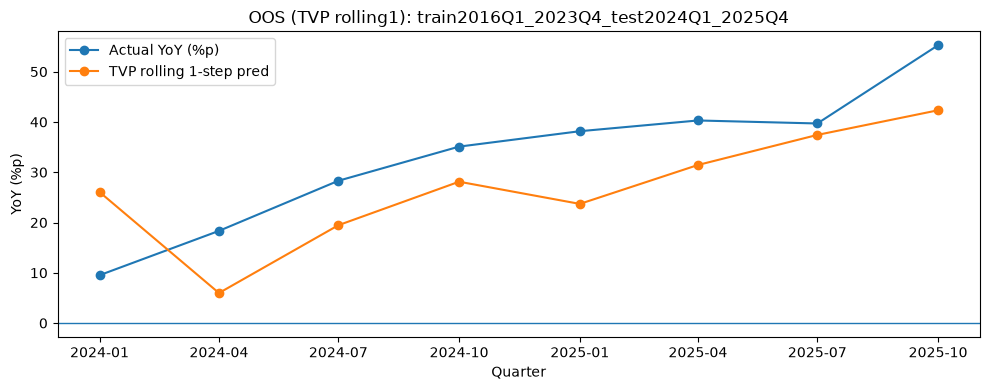

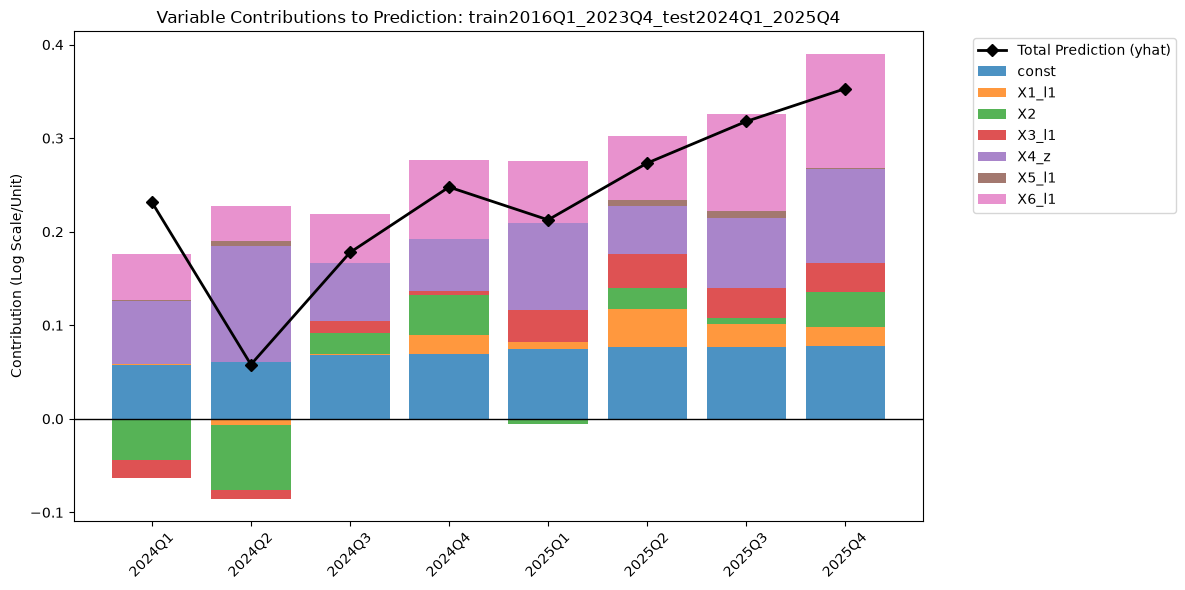

In [6]:
# ----------------------------
# Run backtests
# ----------------------------
all_summaries = []
oos_sheets = {}
ols_sheets = {}
vif_sheets = {}

for cfg in PERIODS:
    name = cfg["name"]
    train_start_ts = q_to_ts(cfg["train_start"])
    train_end_ts = q_to_ts(cfg["train_end"])
    test_start_ts = q_to_ts(cfg["test_start"])
    test_end_ts = q_to_ts(cfg["test_end"])

    cols = ["quarter", "qdate", Y] + X_BASE + ["X5_l1","X6_l1"]
    if "yoy_log_dxy" in df.columns:
        cols += ["yoy_log_dxy"]
    d = df[cols].dropna().copy().reset_index(drop=True)

    train = d[(d["qdate"] >= train_start_ts) & (d["qdate"] <= train_end_ts)].copy().reset_index(drop=True)
    test = d[(d["qdate"] >= test_start_ts) & (d["qdate"] <= test_end_ts)].copy().reset_index(drop=True)

    if len(train) < 20:
        raise ValueError(f"[{name}] Train too small: {len(train)} rows")
    if len(test) < 4:
        raise ValueError(f"[{name}] Test too small: {len(test)} rows")

    # X4_raw z-score (train-only, leakage-free)
    mu_b4 = float(train["X4"].mean())
    sd_b4 = float(train["X4"].std(ddof=0))
    sd_b4 = sd_b4 if sd_b4 != 0 else 1.0

    train = train.copy()
    test = test.copy()
    train["X4_z"] = (train["X4"] - mu_b4) / sd_b4
    test["X4_z"] = (test["X4"] - mu_b4) / sd_b4

    xcols = ["X1_l1", "X2", "X3_l1", "X4_z","X5_l1","X6_l1"]

    # TRAIN diagnostics (OLS HAC + VIF) on *raw* (not TVP-standardized) regressors
    ols_tbl = fit_ols_hac(train, Y, xcols, hac_lags=HAC_LAGS)
    vif_tbl = vif_table(train, xcols)
    ols_sheets[name] = ols_tbl
    vif_sheets[name] = vif_tbl

    print(f"\n=== [{name}] TRAIN OLS(HAC{HAC_LAGS}) coef/t/p ===")
    print(ols_tbl.to_string(index=False))
    print(f"\n=== [{name}] TRAIN VIF ===")
    print(vif_tbl.to_string(index=False))

    # TVP rolling 1-step
    oos_df, _, _, _,coef = tvp_rolling1(
        train_df=train,
        test_df=test,
        y_col=Y,
        x_cols=xcols,
        standardize_x=STANDARDIZE_ALL_X_FOR_TVP,
        maxiter=TVP_MAXITER
    )
    
    print(oos_df)
    print("coef : ", coef)

    met = oos_metrics(oos_df[Y], oos_df["pred_1step"])
    met.update({
        "name": name,
        "train_start": cfg["train_start"],
        "train_end": cfg["train_end"],
        "test_start": cfg["test_start"],
        "test_end": cfg["test_end"],
        "n_train": len(train),
        "n_test": len(test),
        "standardize_x_tvp": STANDARDIZE_ALL_X_FOR_TVP,
    })
    all_summaries.append(met)

    oos_df = oos_df.copy()
    oos_df["actual_pp"] = (np.exp(oos_df[Y]) - 1) * 100
    oos_df["pred_pp"] = (np.exp(oos_df["pred_1step"]) - 1) * 100
    oos_df["err_pp"] = oos_df["actual_pp"] - oos_df["pred_pp"]

    # attach narrative DXY yoy (context only)
    if "yoy_log_dxy" in test.columns:
        oos_df = oos_df.merge(test[["quarter", "yoy_log_dxy"]], on="quarter", how="left")

    oos_sheets[name] = oos_df

    # Plot
    plt.figure(figsize=(10, 4))
    plt.plot(oos_df["qdate"], oos_df["actual_pp"], marker="o", label="Actual YoY (%p)")
    plt.plot(oos_df["qdate"], oos_df["pred_pp"], marker="o", label="TVP rolling 1-step pred")
    plt.axhline(0, linewidth=1)
    plt.title(f"OOS (TVP rolling1): {name}")
    plt.ylabel("YoY (%p)")
    plt.xlabel("Quarter")
    plt.legend()
    plt.tight_layout()

    import os

    #OUT_DIR = r"D:\projects\pds_university\2605_gold_price"
    #os.makedirs(OUT_DIR, exist_ok=True)

    #png = os.path.join(OUT_DIR, f"tvp_oos_{name}.png")
    plt.savefig(f"tvp_oos_{name}.png", dpi=200)
    
    plt.show()
    plt.close()
    
    
    import matplotlib.pyplot as plt

    # ---------------------------------------------------------
    # 1. 기여도 계산 (Contribution Analysis) - 수정본
    # ---------------------------------------------------------
    contrib_df = coef[coef['qdate'] >= test_start_ts].copy().reset_index(drop=True)

    # train과 test를 합쳐서 X4_z가 포함된 전체 데이터를 복원
    full_d = pd.concat([train, test], ignore_index=True).copy()

    # TVP 내부 표준화 로직 재현
    full_d_std = full_d.copy()
    if STANDARDIZE_ALL_X_FOR_TVP:
        # 정확히 train 구간의 데이터 개수만큼만 잘라서 통계량 계산 (Data Leakage 방지)
        mu = train[xcols].mean()
        sd = train[xcols].std(ddof=0).replace(0, 1.0)
        full_d_std[xcols] = (full_d[xcols] - mu) / sd

    # OOS(테스트) 구간의 표준화된 변수값만 필터링
    x_test_std = full_d_std[full_d_std['qdate'] >= test_start_ts][xcols].reset_index(drop=True)

    # 실제 기여도 계산
    contribution = pd.DataFrame({'qdate': contrib_df['qdate'], 'quarter': contrib_df['quarter']})
    contribution['const'] = contrib_df['const']

    for col in xcols:
        contribution[col] = contrib_df[col] * x_test_std[col]

    # ---------------------------------------------------------
    # 2. Stacked Bar Chart 시각화
    # ---------------------------------------------------------
    plt.figure(figsize=(12, 6))
    bottom_pos = np.zeros(len(contribution))
    bottom_neg = np.zeros(len(contribution))

    # 변수별로 막대 쌓기
    plot_cols = ['const'] + xcols
    for col in plot_cols:
        vals = contribution[col]
        # 양수 기여도는 위로, 음수 기여도는 아래로 쌓기 위한 처리
        plt.bar(contribution['quarter'], vals, 
                bottom=np.where(vals > 0, bottom_pos, bottom_neg), 
                label=col, alpha=0.8)

        bottom_pos += np.maximum(vals, 0)
        bottom_neg += np.minimum(vals, 0)

    # 실제 예측값(yhat)을 라인으로 겹쳐서 표현하면 기여도 합계와 일치하는지 확인 가능해.
    plt.plot(contribution['quarter'], oos_df['pred_1step'], 
             color='black', marker='D', linewidth=2, label='Total Prediction (yhat)')

    plt.axhline(0, color='black', linewidth=1)
    plt.title(f"Variable Contributions to Prediction: {name}")
    plt.ylabel("Contribution (Log Scale/Unit)")
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig(f"contribution_bar_{name}.png", dpi=200)
    plt.show()

# NEW VERSION

In [7]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

def forecast_tvp_multistep(
    df: pd.DataFrame,
    date_col: str,
    train_end_date: str,
    y_col: str,
    x_cols: list[str],
    standardize_x: bool = True,
    maxiter: int = 3000
) -> pd.DataFrame:
    """
    통합 데이터프레임과 train_end_date를 받아, Train 구간 파라미터로 학습한 뒤 
    Test 구간(train_end_date 이후)의 Feature(X)를 활용하여 Multi-step Dynamic 예측을 수행합니다.

    Parameters:
    ----------
    df : pd.DataFrame
        Train 및 Test 기간 데이터가 모두 포함된 통합 데이터프레임 (날짜 오름차순 정렬 필요)
    date_col : str
        날짜/분기 컬럼명 (예: 'qdate' 또는 'quarter')
    train_end_date : str or pd.Timestamp
        Train 기간의 마지막 날짜 (예: '2024-12-31' 또는 '2024Q4')
    y_col : str
        타겟 변수(Y) 컬럼명
    x_cols : list[str]
        외생 설명 변수(X) 컬럼명 리스트
    standardize_x : bool, default True
        Train 기준 통계량(mean, std)으로 X 변수 표준화 여부 (Data Leakage 방지)
    maxiter : int, default 3000
        최적화 최대 반복 횟수

    Returns:
    -------
    pd.DataFrame
        train_end_date 이후(Test 구간) 데이터에 1~N step 예측값('pred_multistep')이 추가된 데이터프레임
    """
    data = df.copy().sort_values(by=date_col).reset_index(drop=True)

    # 1. Train / Test 구간 분리 인덱스 탐색
    # train_end_date 이하인 구간까지를 Train으로 설정
    train_mask = data[date_col] <= pd.to_datetime(train_end_date)
    test_start_idx = train_mask.sum()

    if test_start_idx == 0:
        raise ValueError(f"train_end_date ({train_end_date}) 이전 데이터가 존재하지 않습니다.")
    if test_start_idx >= len(data):
        raise ValueError(f"train_end_date ({train_end_date}) 이후의 Test 구간 데이터가 존재하지 않습니다.")

    tr_data = data.iloc[:test_start_idx].copy()

    # 2. Train 기준 X 변수 표준화 (Data Leakage 방지)
    mu, sd = None, None
    if standardize_x:
        mu = tr_data[x_cols].mean()
        sd = tr_data[x_cols].std(ddof=0).replace(0, 1.0)
        
        # 전체 데이터에 Train의 mu, sd 적용
        data[x_cols] = (data[x_cols] - mu) / sd
        tr_data[x_cols] = (tr_data[x_cols] - mu) / sd

    # ---------------------------------------------------------
    # [Step 1. Train] Train 구간 데이터만 사용하여 TVP SARIMAX 피팅
    # ---------------------------------------------------------
    exog_tr = np.column_stack([np.ones(len(tr_data)), tr_data[x_cols].astype(float).to_numpy()])
    mod_tr = sm.tsa.SARIMAX(
        endog=tr_data[y_col].astype(float).to_numpy(),
        exog=exog_tr,
        order=(0, 0, 0),
        trend="n",
        time_varying_regression=True,
        mle_regression=False,
    )
    
    try:
        res_tr = mod_tr.fit(disp=False, maxiter=maxiter)
    except Exception:
        res_tr = mod_tr.fit(disp=False, maxiter=maxiter * 2, method="powell")

    # ---------------------------------------------------------
    # [Step 2. Inference] 학습된 파라미터를 전체 데이터에 고정(filter) 후 Dynamic 예측
    # ---------------------------------------------------------
    exog_full = np.column_stack([np.ones(len(data)), data[x_cols].astype(float).to_numpy()])
    mod_full = sm.tsa.SARIMAX(
        endog=data[y_col].astype(float).to_numpy(),
        exog=exog_full,
        order=(0, 0, 0),
        trend="n",
        time_varying_regression=True,
        mle_regression=False,
    )
    # Train에서 피팅된 파라미터(res_tr.params)만 주입하여 칼만 필터링 수행
    res_f = mod_full.filter(res_tr.params)

    # dynamic=test_start_idx: Test 시작점 이후부터 실제 Y 실측치 업데이트를 끊고,
    # 모델 자신의 이전 단계 예측값(\hat{Y})을 시차항(AR)으로 재귀적 반영하여 미래 N-step을 연속 예측함
    start_i = test_start_idx
    end_i = len(data) - 1
    pred = res_f.get_prediction(start=start_i, end=end_i, dynamic=True)
    yhat = np.asarray(pred.predicted_mean)

    # 3. Test 기간 결과 데이터프레임 구성 및 반환
    # 원본 Scale 복원을 대비해 원래 입력 데이터 기준으로 출력 추출
    test_out = df.iloc[test_start_idx:].copy().reset_index(drop=True)
    test_out["pred_multistep"] = yhat
    test_out["horizon_step"] = np.arange(1, len(test_out) + 1)

    return test_out

  quarter  horizon_step  yoy_log_gold  pred_multistep          실제가  \
0  2025Q1             1      0.323238        0.274673  2859.619048   
1  2025Q2             2      0.338580        0.303134  3280.352459   
2  2025Q3             3      0.334315        0.290401  3456.543846   
3  2025Q4             4      0.439950        0.312916  4135.235484   

           예측가  
0  2724.059796  
1  3166.113861  
2  3308.036795  
3  3641.918983  


<Axes: xlabel='quarter'>

C:\PDS\Streamlit\streamlit_env\Lib\site-packages\IPython\core\events.py:101: UserWarning: Glyph 49892 (\N{HANGUL SYLLABLE SIL}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
C:\PDS\Streamlit\streamlit_env\Lib\site-packages\IPython\core\events.py:101: UserWarning: Glyph 51228 (\N{HANGUL SYLLABLE JE}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
C:\PDS\Streamlit\streamlit_env\Lib\site-packages\IPython\core\events.py:101: UserWarning: Glyph 44032 (\N{HANGUL SYLLABLE GA}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
C:\PDS\Streamlit\streamlit_env\Lib\site-packages\IPython\core\events.py:101: UserWarning: Glyph 50696 (\N{HANGUL SYLLABLE YE}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
C:\PDS\Streamlit\streamlit_env\Lib\site-packages\IPython\core\events.py:101: UserWarning: Glyph 52769 (\N{HANGUL SYLLABLE CEUG}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
C:\PDS\Streamlit\streamlit_env\Lib\site-packages\IPython\core\pylabtools

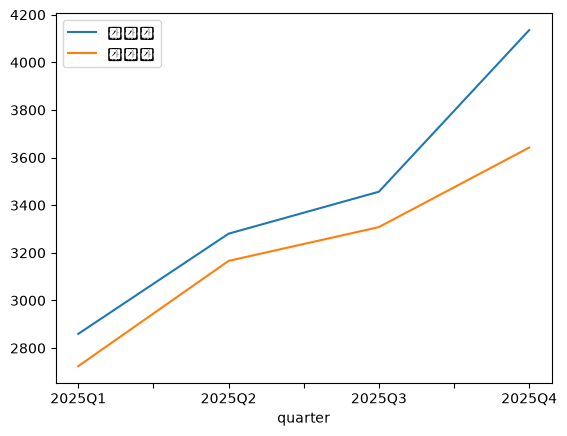

In [8]:
import datetime

full_d = full_d.loc[full_d['qdate']>=datetime.datetime(2016,1,1)]
full_d = full_d.reset_index()
full_d = full_d.drop('index',axis=1)


# 사용법 예시
output_df = forecast_tvp_multistep(
    df=full_d,                           # Train + Test가 모두 포함된 데이터프레임
    date_col="qdate",                    # 날짜/시간 컬럼명
    train_end_date="2024-12-31",         # Train이 끝나는 날짜
    y_col=Y,                             # 예측 타겟 변수
    x_cols=xcols,                        # 미래값(2025Q1~2025Q4)이 포함된 Feature 리스트
    standardize_x=True
)

# 예측 yoy_log_gold를 가격 레벨로 역산: price_t = price_(t-4분기) * exp(pred)
# (이 구간은 이미 지난 분기라 실제가가 있으므로 체이닝 없이 4분기 전 실제가를 바로 씀)
price_lookup = df.dropna(subset=["gold"]).set_index("quarter")["gold"]
output_df["prev_year_quarter"] = output_df["quarter"].apply(
    lambda q: str(pd.Period(q, freq="Q") - 4)
)
output_df["예측가"] = (
    output_df["prev_year_quarter"].map(price_lookup) * np.exp(output_df["pred_multistep"])
)
output_df["실제가"] = output_df["quarter"].map(price_lookup)

# Output 출력 예시
print(output_df[["quarter", "horizon_step", Y, "pred_multistep", "실제가", "예측가"]])

output_df[["quarter", "실제가", "예측가"]].set_index('quarter').plot()

  quarter  horizon_step  yoy_log_gold  pred_multistep          실제가  \
0  2024Q1             1      0.090916        0.231598  2069.796032   
1  2024Q2             2      0.168333        0.150933  2338.175806   
2  2024Q3             3      0.249223        0.171549  2474.291538   
3  2024Q4             4      0.300806        0.224074  2663.376613   
4  2025Q1             5      0.323238        0.142294  2859.619048   
5  2025Q2             6      0.338580        0.172987  3280.352459   
6  2025Q3             7      0.334315        0.189929  3456.543846   
7  2025Q4             8      0.439950        0.223794  4135.235484   

           예측가  
0  2382.456088  
1  2297.842594  
2  2289.378605  
3  2466.654734  
4  2386.298972  
5  2779.740887  
6  2991.822954  
7  3331.386342  


C:\PDS\Streamlit\streamlit_env\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


<Axes: xlabel='quarter'>

C:\PDS\Streamlit\streamlit_env\Lib\site-packages\IPython\core\events.py:101: UserWarning: Glyph 49892 (\N{HANGUL SYLLABLE SIL}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
C:\PDS\Streamlit\streamlit_env\Lib\site-packages\IPython\core\events.py:101: UserWarning: Glyph 51228 (\N{HANGUL SYLLABLE JE}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
C:\PDS\Streamlit\streamlit_env\Lib\site-packages\IPython\core\events.py:101: UserWarning: Glyph 44032 (\N{HANGUL SYLLABLE GA}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
C:\PDS\Streamlit\streamlit_env\Lib\site-packages\IPython\core\events.py:101: UserWarning: Glyph 50696 (\N{HANGUL SYLLABLE YE}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
C:\PDS\Streamlit\streamlit_env\Lib\site-packages\IPython\core\events.py:101: UserWarning: Glyph 52769 (\N{HANGUL SYLLABLE CEUG}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
C:\PDS\Streamlit\streamlit_env\Lib\site-packages\IPython\core\pylabtools

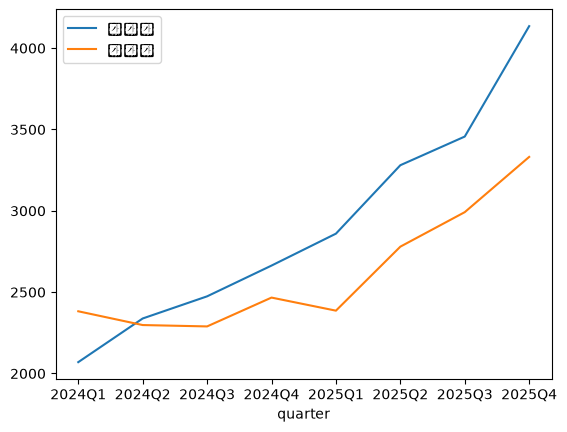

In [9]:
import datetime

full_d = full_d.loc[full_d['qdate']>=datetime.datetime(2016,1,1)]
full_d = full_d.reset_index()
full_d = full_d.drop('index',axis=1)


# 사용법 예시
output_df = forecast_tvp_multistep(
    df=full_d,                           # Train + Test가 모두 포함된 데이터프레임
    date_col="qdate",                    # 날짜/시간 컬럼명
    train_end_date="2023-12-31",         # Train이 끝나는 날짜
    y_col=Y,                             # 예측 타겟 변수
    x_cols=xcols,                        # 미래값(2025Q1~2025Q4)이 포함된 Feature 리스트
    standardize_x=True
)

# 예측 yoy_log_gold를 가격 레벨로 역산: price_t = price_(t-4분기) * exp(pred)
# (이 구간은 이미 지난 분기라 실제가가 있으므로 체이닝 없이 4분기 전 실제가를 바로 씀)
price_lookup = df.dropna(subset=["gold"]).set_index("quarter")["gold"]
output_df["prev_year_quarter"] = output_df["quarter"].apply(
    lambda q: str(pd.Period(q, freq="Q") - 4)
)
output_df["예측가"] = (
    output_df["prev_year_quarter"].map(price_lookup) * np.exp(output_df["pred_multistep"])
)
output_df["실제가"] = output_df["quarter"].map(price_lookup)

# Output 출력 예시
print(output_df[["quarter", "horizon_step", Y, "pred_multistep", "실제가", "예측가"]])

output_df[["quarter", "실제가", "예측가"]].set_index('quarter').plot()

   quarter  horizon_step  yoy_log_gold  pred_multistep          실제가  \
0   2023Q1             1      0.006772        0.000810  1889.918750   
1   2023Q2             2      0.054788        0.088223  1975.927500   
2   2023Q3             3      0.109238        0.207656  1928.478906   
3   2023Q4             4      0.133072        0.184207  1971.487705   
4   2024Q1             5      0.090916        0.299684  2069.796032   
5   2024Q2             6      0.168333        0.210289  2338.175806   
6   2024Q3             7      0.249223        0.203861  2474.291538   
7   2024Q4             8      0.300806        0.246918  2663.376613   
8   2025Q1             9      0.323238        0.164529  2859.619048   
9   2025Q2            10      0.338580        0.194740  3280.352459   
10  2025Q3            11      0.334315        0.194950  3456.543846   
11  2025Q4            12      0.439950        0.231799  4135.235484   

            예측가  
0   1878.684289  
1   2043.110123  
2   2127.929562  
3   

C:\PDS\Streamlit\streamlit_env\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


<Axes: xlabel='quarter'>

C:\PDS\Streamlit\streamlit_env\Lib\site-packages\IPython\core\events.py:101: UserWarning: Glyph 49892 (\N{HANGUL SYLLABLE SIL}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
C:\PDS\Streamlit\streamlit_env\Lib\site-packages\IPython\core\events.py:101: UserWarning: Glyph 51228 (\N{HANGUL SYLLABLE JE}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
C:\PDS\Streamlit\streamlit_env\Lib\site-packages\IPython\core\events.py:101: UserWarning: Glyph 44032 (\N{HANGUL SYLLABLE GA}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
C:\PDS\Streamlit\streamlit_env\Lib\site-packages\IPython\core\events.py:101: UserWarning: Glyph 50696 (\N{HANGUL SYLLABLE YE}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
C:\PDS\Streamlit\streamlit_env\Lib\site-packages\IPython\core\events.py:101: UserWarning: Glyph 52769 (\N{HANGUL SYLLABLE CEUG}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
C:\PDS\Streamlit\streamlit_env\Lib\site-packages\IPython\core\pylabtools

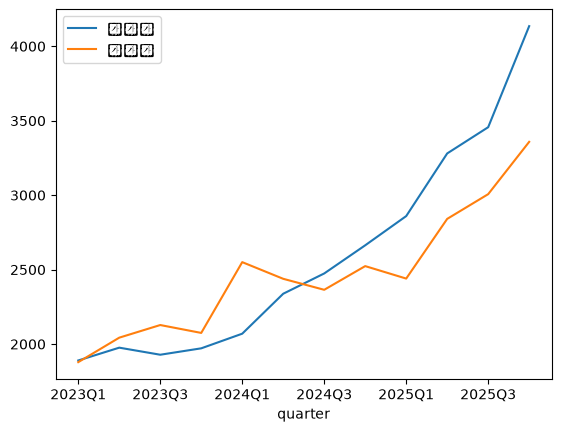

In [10]:
import datetime

full_d = full_d.loc[full_d['qdate']>=datetime.datetime(2016,1,1)]
full_d = full_d.reset_index()
full_d = full_d.drop('index',axis=1)


# 사용법 예시
output_df = forecast_tvp_multistep(
    df=full_d,                           # Train + Test가 모두 포함된 데이터프레임
    date_col="qdate",                    # 날짜/시간 컬럼명
    train_end_date="2022-12-31",         # Train이 끝나는 날짜
    y_col=Y,                             # 예측 타겟 변수
    x_cols=xcols,                        # 미래값(2025Q1~2025Q4)이 포함된 Feature 리스트
    standardize_x=True
)

# 예측 yoy_log_gold를 가격 레벨로 역산: price_t = price_(t-4분기) * exp(pred)
# (이 구간은 이미 지난 분기라 실제가가 있으므로 체이닝 없이 4분기 전 실제가를 바로 씀)
price_lookup = df.dropna(subset=["gold"]).set_index("quarter")["gold"]
output_df["prev_year_quarter"] = output_df["quarter"].apply(
    lambda q: str(pd.Period(q, freq="Q") - 4)
)
output_df["예측가"] = (
    output_df["prev_year_quarter"].map(price_lookup) * np.exp(output_df["pred_multistep"])
)
output_df["실제가"] = output_df["quarter"].map(price_lookup)

# Output 출력 예시
print(output_df[["quarter", "horizon_step", Y, "pred_multistep", "실제가", "예측가"]])

output_df[["quarter", "실제가", "예측가"]].set_index('quarter').plot()

  quarter  horizon_step  yoy_log_gold  pred_multistep          실제가  \
0  2025Q2             1      0.338580        0.318283  3280.352459   
1  2025Q3             2      0.334315        0.319955  3456.543846   
2  2025Q4             3      0.439950        0.353315  4135.235484   

           예측가  
0  3214.442608  
1  3407.261620  
2  3792.060201  


<Axes: xlabel='quarter'>

C:\PDS\Streamlit\streamlit_env\Lib\site-packages\IPython\core\events.py:101: UserWarning: Glyph 49892 (\N{HANGUL SYLLABLE SIL}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
C:\PDS\Streamlit\streamlit_env\Lib\site-packages\IPython\core\events.py:101: UserWarning: Glyph 51228 (\N{HANGUL SYLLABLE JE}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
C:\PDS\Streamlit\streamlit_env\Lib\site-packages\IPython\core\events.py:101: UserWarning: Glyph 44032 (\N{HANGUL SYLLABLE GA}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
C:\PDS\Streamlit\streamlit_env\Lib\site-packages\IPython\core\events.py:101: UserWarning: Glyph 50696 (\N{HANGUL SYLLABLE YE}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
C:\PDS\Streamlit\streamlit_env\Lib\site-packages\IPython\core\events.py:101: UserWarning: Glyph 52769 (\N{HANGUL SYLLABLE CEUG}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
C:\PDS\Streamlit\streamlit_env\Lib\site-packages\IPython\core\pylabtools

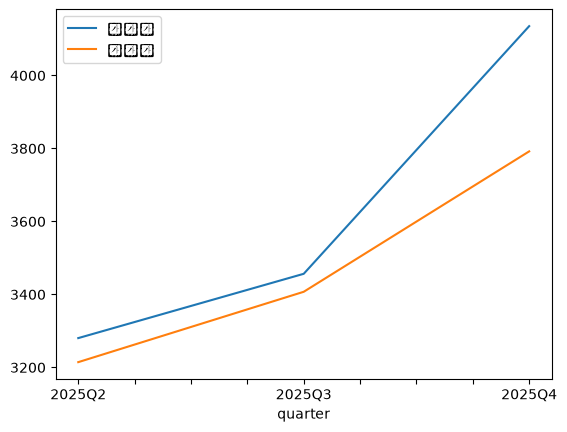

In [11]:
import datetime

full_d = full_d.loc[full_d['qdate']>=datetime.datetime(2016,1,1)]
full_d = full_d.reset_index()
full_d = full_d.drop('index',axis=1)


# 사용법 예시
output_df = forecast_tvp_multistep(
    df=full_d,                           # Train + Test가 모두 포함된 데이터프레임
    date_col="qdate",                    # 날짜/시간 컬럼명
    train_end_date="2025-03-31",         # Train이 끝나는 날짜
    y_col=Y,                             # 예측 타겟 변수
    x_cols=xcols,                        # 미래값(2025Q1~2025Q4)이 포함된 Feature 리스트
    standardize_x=True
)

# 예측 yoy_log_gold를 가격 레벨로 역산: price_t = price_(t-4분기) * exp(pred)
# (이 구간은 이미 지난 분기라 실제가가 있으므로 체이닝 없이 4분기 전 실제가를 바로 씀)
price_lookup = df.dropna(subset=["gold"]).set_index("quarter")["gold"]
output_df["prev_year_quarter"] = output_df["quarter"].apply(
    lambda q: str(pd.Period(q, freq="Q") - 4)
)
output_df["예측가"] = (
    output_df["prev_year_quarter"].map(price_lookup) * np.exp(output_df["pred_multistep"])
)
output_df["실제가"] = output_df["quarter"].map(price_lookup)

# Output 출력 예시
print(output_df[["quarter", "horizon_step", Y, "pred_multistep", "실제가", "예측가"]])

output_df[["quarter", "실제가", "예측가"]].set_index('quarter').plot()